<a href="https://colab.research.google.com/github/T1toh/30Days_of_SQL/blob/main/MODULE_4_%7C_LESSON_4_Advanced_Correlation_Structures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CAPSTONE REVIEW**

## MODULE 4 | LESSON 4: Advanced Correlation Structures

| | |
|:---|:---|
|**Reading Time** | 4h |
|**Prior Knowledge** | Black-Scholes model, stochastic calculus, PDEs, time series analysis, GARCH models, option pricing |
|**Keywords** | stochastic volatility, Heston model, local volatility, CEV model, volatility surfaces, implied volatility, variance swaps, VIX, jump-diffusion, calibration, state space models |

---

## 1. Correlation Risk in Portfolios Using Spectral Decomposition

### 1.1 Understanding Correlation Risk Through Eigenvalues

For the purposes of risk management, correlation is the friend who borrows your umbrella on a sunny day and disappears when it rains. It pays to understand why this betrayal happens with such regularity.

A bit more precisely, spectral decomposition reveals that any correlation matrix $R$ can be written as $R = \Gamma \Lambda \Gamma^T$, where the eigenvectors in $\Gamma$ represent independent risk factors and the eigenvalues in $\Lambda$ measure their importance. This isn't mathematical decoration. It's the key to understanding why your carefully diversified portfolio suddenly acts like a single risky bet.

Note that portfolio variance becomes surprisingly transparent through this lens. With portfolio weights $w$, we have:

$$\sigma_p^2 = w^T \Sigma w = \sum_{k=1}^n \lambda_k (v_k^T D w)^2$$

The largest eigenvalue typically captures market risk – that factor which moves all assets together. In calm markets, this might explain 30-40% of total variance. (Manageable, right?) But here's where correlation stabs you in the back: during crises, this eigenvalue can double, suddenly explaining 70% of returns. Your stock-picking skills? Practically irrelevant when one factor dominates everything.

It pays to think of eigenvalues as a health diagnostic for your portfolio. When the largest eigenvalue starts growing ominously – like a tumor on an X-ray – correlation risk is metastasizing. Exercise 1 should convince you that tracking this metric would have warned you before every major market crisis.

### 1.2 Spectral Risk Measures

Traditional risk measures treat correlation as if it were carved in stone. (Why would we assume such stability?) Spectral risk measures explicitly acknowledge that eigenvalues shift under stress.

Define the spectral risk contribution of factor $k$ as the fraction of total portfolio risk it explains:

$$SRC_k = \frac{\lambda_k (v_k^T D w)^2}{\sigma_p^2}$$

This measure acts like a correlation seismograph. When $SRC_1$ rises above historical norms, systematic risk is building. You're no longer diversified – you're making a single large bet disguised as many small ones.

Note that eigenvalues alone tell only half the story. The condition number $\kappa = \lambda_{max}/\lambda_{min}$ reveals how sensitive your optimization is to correlation estimation errors. Think of it as measuring how wobbly your portfolio foundation is. When $\kappa > 100$, tiny correlation changes create earthquake-level portfolio disruptions. (Remember LTCM? Their condition number was astronomical.)

The effective number of bets provides another sobering metric:

$$N_{eff} = \frac{n^2}{\sum_{k=1}^n \lambda_k^2}$$

With 100 assets but $N_{eff} = 10$, you're fooling yourself about diversification. Correlation has pickpocketed 90% of your independent bets while you weren't looking.

### 1.3 Dynamic Spectral Analysis

Static analysis captures snapshots. Dynamic analysis reveals the horror movie.

Consider what happened during 2008. Pre-crisis eigenvalues showed normal dispersion – largest one at 35%, others trailing off nicely. As crisis approached, that first eigenvalue grew like a malignant cell, reaching 60% by September. Simultaneously, smaller eigenvalues shriveled. Diversification opportunities evaporated faster than liquidity in a bank run.

But the eigenvectors tell an even scarier story. The first eigenvector initially reflected broad market exposure. By mid-crisis, it had rotated to load heavily on financials. (Why does this matter?) Because portfolios hedged against pre-crisis factors found themselves naked when factors shape-shifted. It's like preparing for a flood and getting hit by a wildfire instead.

This motivates continuous spectral monitoring – not just eigenvalue magnitudes but eigenvector stability too. Large rotations signal regime changes. When eigenvectors start dancing, it's time to reduce risk. The mathematics is warning you that the rules have changed.

## 2. Correlation Breakdowns in Crises

### 2.1 Anatomy of Correlation Breakdowns

Correlation breakdowns follow a script. Understanding this script might save your portfolio.

First comes contagion – a shock in one market infects others through channels invisible during calm periods. The 1997 Asian crisis began with Thai baht devaluation. Within weeks, Latin American markets crashed. (What connected Thailand to Brazil?) Margin calls forced liquidation across unrelated positions. Risk models demanded simultaneous de-risking. Fear overwhelmed fundamental analysis.

Flight-to-quality represents contagion's mirror image. As risky assets converge toward perfect correlation, safe havens suddenly offer actual diversification. Treasury bonds, gold, Swiss francs become lifeboats – but only if you grabbed them before the ship started sinking. During March 2020's COVID panic, even these traditional havens wobbled initially. (Everyone needed cash, not safety.)

Speed kills in correlation breakdowns. Gradual increases allow adjustment; sudden spikes don't. The 2007 quant crisis saw correlations among "market-neutral" strategies spike within days. Funds that survived had either pre-positioned for correlation risk or maintained deep liquidity reserves. The rest? History.

### 2.2 Mathematical Models of Breakdown

While breakdowns feel chaotic, mathematics can help us prepare. (Would you rather have a map or wander blindly?)

Threshold models capture regime-switching brutality:

$$\rho_{ij,t} = \begin{cases}
\rho_{ij}^{normal} & \text{if } VIX_t < \tau \\
\rho_{ij}^{crisis} & \text{if } VIX_t \geq \tau
\end{cases}$$

Real markets prefer smooth transitions. Nobody rings a bell at correlation regime changes:

$$\rho_{ij,t} = \rho_{ij}^{normal} + (\rho_{ij}^{crisis} - \rho_{ij}^{normal}) \cdot \Phi\left(\frac{VIX_t - \tau}{\gamma}\right)$$

Dynamic conditional correlation models let correlations evolve continuously. During crises, the innovation term dominates, driving correlations toward one faster than you can say "diversification."

Network models offer another lens. Define correlation networks where edges represent pairwise correlations. Crisis equals network collapse – previously distant nodes suddenly hold hands. Monitoring network density provides early warning. When your sparse network starts looking like a hairball, trouble's brewing.

### 2.3 Historical Evidence and Patterns

History doesn't repeat, but correlation breakdowns definitely rhyme. (Why do we keep getting surprised?)

The 1987 crash wrote the playbook. International equity correlations averaged 0.4 pre-crash. Within days? Above 0.8. But here's the crucial pattern: equity-bond correlations turned sharply negative. Risk assets converged while safe assets diverged. This bifurcation appears in every subsequent crisis. It's correlation's signature move.

LTCM showed how leverage amplifies correlation risk. The fund assumed low correlations between Russian bonds, Danish mortgages, and equity pairs. Their own distressed selling created the correlations they'd bet against. When you're large enough, you become the correlation event. (Ironic? Tragic? Both?)

The 2008 crisis revealed correlation's path dependence. Initial subprime shocks seemed contained. But losses created more losses, spreading correlations like cracks in ice. By September, Brazilian equities correlated with Danish covered bonds. The mechanism? Global deleveraging created one dominant factor: survival.

COVID-19 added a twist. March 2020 saw typical correlation spikes. But unprecedented stimulus quickly restored differentiation. Technology stocks decoupled from airlines within months. The lesson? Correlation breakdowns can heal given sufficient policy firepower. But scar tissue remains.

## 3. Copula Approaches to Dependence

### 3.1 Beyond Linear Correlation

Pearson correlation captures only linear dependence. For extreme events, that's like using a thermometer to measure earthquakes.

Sklar's theorem provides escape velocity. Any multivariate distribution $F$ can be decomposed:

$$F(x_1, ..., x_n) = C(F_1(x_1), ..., F_n(x_n))$$

The copula $C$ captures pure dependence structure, separated from marginal behaviors. (Why separate them?) Because your assets might have wildly different distributions but similar crisis behaviors. Copulas let you model both accurately.

The Gaussian copula extends correlation to non-normal worlds:

$$C_R^{Gauss}(u_1, ..., u_n) = \Phi_R(\Phi^{-1}(u_1), ..., \Phi^{-1}(u_n))$$

Despite starring in the CDO disaster, Gaussian copulas work fine when tail dependence doesn't matter. (How often does tail dependence not matter in finance? Rarely.)

Student-t copulas add crucial realism:

$$C_{R,\nu}^t(u_1, ..., u_n) = t_{R,\nu}(t_\nu^{-1}(u_1), ..., t_\nu^{-1}(u_n))$$

That parameter $\nu$ controls tail dependence. Small $\nu$ means extreme events cluster together – exactly what markets do. It's the mathematical acknowledgment that crashes are contagious.

### 3.2 Tail Dependence and Asymmetry

Markets treat upside and downside differently. (Ever notice how crashes are faster than rallies?) Traditional correlation pretends otherwise.

Tail dependence coefficients quantify this asymmetry:

$$\lambda_L = \lim_{u \to 0^+} P(V \leq u | U \leq u)$$

Gaussian copulas have zero tail dependence – they assume extreme events are independent. Financial history laughs at this assumption. Student-t copulas show symmetric tail dependence. Better, but still wrong.

Enter the Clayton copula, capturing lower tail dependence:

$$C_\theta^{Clayton}(u,v) = (u^{-\theta} + v^{-\theta} - 1)^{-1/\theta}$$

Perfect for modeling crisis clustering while allowing calm-period independence. The Gumbel copula does the opposite – upper tail dependence for bubble modeling. Real portfolios often need mixtures. Markets are complicated. (Surprised?)

### 3.3 Copula Selection and Estimation

Choosing copulas blends science with art. Visual diagnostics start the process.

Chi-plots reveal hidden dependence patterns. Under independence, these scatter around zero. Patterns in the tails scream "wrong copula!" K-plots compare empirical against theoretical dependence. Deviations from 45-degree lines indicate misspecification.

Information criteria provide formal selection:

$$AIC = -2\ln L + 2k$$

But don't worship statistics. Economic reasoning matters more. Equity pairs likely show symmetric tail dependence (Student-t). Equity-bond pairs might show asymmetry (mixtures). Let economics guide, statistics confirm.

## 4. Multi-Asset Correlation Modeling

### 4.1 High-Dimensional Challenges

Two-asset correlation is kindergarten. Hundreds of assets? That's PhD-level complexity.

The curse of dimensionality strikes hard. With $n$ assets, you need $n(n-1)/2$ correlation parameters. For 500 assets? 124,750 parameters. You'd need centuries of data for reliable estimation. (Markets barely give you decades.)

Positive definiteness constraints bite harder in high dimensions. You can't specify correlations arbitrarily – mathematics rebels. These constraints grow increasingly restrictive as dimension increases. What looks reasonable pairwise might be impossible jointly.

Estimation errors compound multiplicatively. Each correlation has sampling error. In high dimensions, errors accumulate like compound interest, but in reverse. Your carefully optimized portfolio might be optimizing against pure noise.

### 4.2 Factor Models and Dimension Reduction

Factor models rescue us from dimensional disaster. Instead of modeling all correlations, model common factors:

$$r_i = \beta_i' f + \epsilon_i$$

With $k$ factors for $n$ assets, parameters shrink from $O(n^2)$ to $O(nk)$. For 500 assets and 10 factors? You've cut 124,750 parameters to 5,000. That's 96% reduction – the difference between impossible and tractable.

Statistical factors emerge from data via PCA. Economic factors come from theory: market, size, value, momentum. Which is better? (Trick question.) Use both. Statistical factors ensure fit; economic factors provide interpretation.

The key insight: most correlation structure comes from a few dominant factors. The rest is noise. By focusing on what matters, factor models make the impossible possible.

### 4.3 Shrinkage and Regularization

When dimension reduction isn't enough, shrink intelligently. Pull extreme correlations toward sensible targets.

Linear shrinkage blends sample with target:

$$\hat{R}_{shrink} = \alpha \hat{R}_{sample} + (1-\alpha) R_{target}$$

The optimal shrinkage intensity balances bias against variance. Too little shrinkage keeps noise; too much destroys signal. Ledoit-Wolf derived the Goldilocks formula – just right.

Non-linear shrinkage improves further by treating each eigenvalue differently. Large eigenvalues (signal) stay; small ones (noise) get squashed. It's like noise-canceling headphones for your correlation matrix.

## 5. Computational Methods: MCMC Methods for Copula Calibration

### 5.1 The Calibration Challenge

Calibrating copulas resembles finding a black cat in a dark room. (The cat might not exist.) Maximum likelihood often fails – non-convex surfaces, numerical instabilities, high dimensions conspire against you.

MCMC methods offer night-vision goggles. Instead of blindly seeking optima, they explore parameter space probabilistically. When the landscape is treacherous, random walking beats determined climbing.

### 5.2 Metropolis-Hastings for Copula Parameters

Metropolis-Hastings navigates parameter space through guided randomness:

1. Start somewhere (anywhere)
2. Propose a random step
3. Accept good steps, sometimes accept bad ones
4. Repeat until convergence

The acceptance probability ensures we spend time in high-probability regions:

$$\alpha = \min\left(1, \frac{p(\theta'|data)}{p(\theta_t|data)}\right)$$

For copulas, this becomes:

$$p(\theta|data) \propto \prod_{t=1}^T c_\theta(u_{1,t}, ..., u_{n,t}) \cdot p(\theta)$$

Tuning proposals requires finesse. Too timid? Convergence crawls. Too bold? Rejection dominates. Adaptive MCMC adjusts proposals based on acceptance history – learning the landscape while exploring it.

### 5.3 Bayesian Copula Selection

Why choose one copula when you can average many? MCMC enables Bayesian model comparison through marginal likelihoods.

Reversible jump MCMC goes further – jumping between copula families mid-sampling. The data reveals which dependence structures matter most. It's like letting the market tell you its correlation personality rather than imposing your assumptions.

## 6. Basket Derivatives and Correlation Sensitivity

### 6.1 Correlation Impact on Basket Option Pricing

Basket options are correlation's favorite victims. Change correlation assumptions, watch values swing wildly.

Consider a simple basket call:

$$Payoff = \max\left(\sum_{i=1}^n w_i S_i(T) - K, 0\right)$$

The basket's volatility depends critically on correlations:

$$\sigma_{basket}^2 = \sum_{i=1}^n \sum_{j=1}^n w_i w_j \sigma_i \sigma_j \rho_{ij}$$

For two assets, varying correlation from -1 to +1 can triple option values. (Would you accept such uncertainty in your pricing?) This sensitivity creates both risk and opportunity – if you understand it.

### 6.2 Correlation Greeks

Just as delta quantifies directional risk, correlation Greeks measure correlation exposure:

$$\frac{\partial V}{\partial \rho_{ij}}$$

For basket options, correlation delta often dominates traditional Greeks. You might be hedged against market moves but naked to correlation shifts. (Comfortable with that?)

Correlation gamma captures convexity:

$$\frac{\partial^2 V}{\partial \rho_{ij}^2}$$

Positive correlation gamma means you profit from correlation volatility. During uncertain times, that's portfolio insurance.

### 6.3 Hedging Correlation Risk

Static hedging uses opposing correlation exposures. Dispersion trading – long index volatility, short constituents – provides natural correlation hedges. When correlations rise, you win.

Dynamic hedging adjusts continuously. But correlation's bounded nature complicates things. Near -1 or +1, hedge ratios explode. It's like trying to hedge as you approach a cliff edge.

Correlation swaps offer direct exposure:

$$Payoff = Notional \times (Realized - Strike)$$

Clean in theory, messy in practice. Illiquid markets and complex settlements limit usefulness. Sometimes the cure is worse than the disease.

## 7. Stress Testing Correlation Assumptions Using Bootstrapping Techniques

### 7.1 Bootstrap Methods for Correlation Uncertainty

Historical correlations are estimates pretending to be facts. Bootstrap methods expose this pretense.

Resample history with replacement:
1. Draw $T$ observations from your $T$ data points
2. Compute correlations
3. Repeat 10,000 times

The resulting distribution shows what you don't know. That 0.6 correlation? Could be 0.4 or 0.75. Your confidence was misplaced.

Block bootstrap preserves time dependence. Instead of individual observations, resample blocks. This maintains autocorrelation structure – crucial for financial data where volatility clusters.

### 7.2 Stress Scenarios via Bootstrap

Bootstrap naturally generates stress scenarios. Use 95th percentile correlations – plausible but painful.

Conditional bootstrap focuses on crisis periods. Weight observations by VIX levels, emphasizing stressed markets. This generates correlation matrices consistent with "bad times" without arbitrary assumptions.

Factor-based bootstrap is even cleverer. Decompose returns into systematic and idiosyncratic parts. Oversample systematic components during stress tests. Correlations rise naturally, mimicking crisis dynamics.

### 7.3 Portfolio Implications

Apply bootstrap correlation matrices to portfolio optimization:

1. Generate 10,000 correlation matrices
2. Optimize each one
3. Examine the portfolio chaos

Wide weight variations indicate dangerous correlation sensitivity. Robust portfolios maintain reasonable performance across the distribution. If your optimal portfolio changes dramatically with correlation tweaks, you're not optimizing – you're gambling.

COVID-19 validated this approach. Portfolios stress-tested via bootstrap suffered less during March 2020 than those using point estimates. Preparation beats prediction.

**Continuing the rolling‑PCA study from the previous lesson**

In the last notebook you  

1. **Monitored $\text{EVR}_1(t)$** — the explained‑variance ratio of the first principal component — over time, and  
2. Saw how $\text{EVR}_1$ surged toward $0.8$ during crisis windows (2008, 2020), signalling systemic co‑movement.

That analysis answered **“How do correlations evolve?”**  
It did **not** answer **“How confident are we in today’s correlation snapshot?”**

Today we close that gap.  
Using the **same nine sector ETFs** you already imported, we will

* hold the window fixed at the latest date,  
* apply a **moving‑block bootstrap** (block length $L = 60$ days) to mimic alternative histories consistent with the observed serial dependence, and  
* examine the sampling distribution of three risk diagnostics you know from Module 4:

$$
\lambda_1 = \text{largest eigenvalue of }\hat R,\qquad
\kappa = \frac{\lambda_{\max}}{\lambda_{\min}},\qquad
\sigma_{EW}^2 = w^{\top}\hat\Sigma w,\; w_i = \tfrac{1}{9}.
$$

These distributions tell us **how wide the error bars are** around the point estimates that fed your rolling‑PCA dashboard — and therefore how much cushion a risk manager should build into leverage or VaR limits.

**Goal for this cell sequence:** quantify the 95 % bootstrap intervals for  
$\lambda_1,\; \kappa,\; \sigma_{EW}^2$ and visualise where the current
estimates sit inside those bands.


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8")

# Load the uploaded CSV file
prices = pd.read_csv("/raw_nine_sectors.csv")

# Check the column names
print(prices.head())
print(prices.columns)

         Date        XLB        XLE        XLF        XLI        XLK  \
0  2007-01-03  23.206045  32.508293  20.802193  24.599379  18.214264   
1  2007-01-04  23.098768  31.916508  20.734585  24.494650  18.495333   
2  2007-01-05  22.944559  32.129089  20.571188  24.410849  18.346991   
3  2007-01-08  22.944559  32.129089  20.661331  24.501623  18.401634   
4  2007-01-09  22.951252  31.853306  20.627531  24.487658  18.425068   

         XLP        XLU        XLV        XLY   ^TNX   ^VIX  
0  16.073259  19.317633  24.321312  30.330456  4.664  12.04  
1  16.097719  19.291386  24.597191  30.322584  4.618  11.51  
2  15.981552  18.945127  24.459248  30.117855  4.646  12.14  
3  16.006004  18.934635  24.488291  30.165094  4.660  12.00  
4  16.042694  18.950369  24.459248  30.330456  4.656  11.91  
Index(['Date', 'XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY',
       '^TNX', '^VIX'],
      dtype='object')



Before stressing, inspect the empirical correlation matrix $ \hat R $.

*We leave returns un‑winsorised here; feel free to clip outliers if your own
diagnostics suggest it.*


Largest eigenvalue lambda_1  = 6.442
Condition number kappa    =  59.4


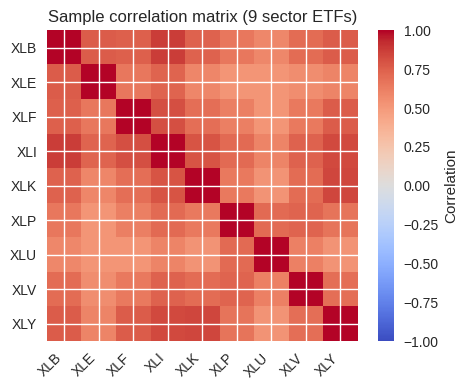

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ensure prices are loaded correctly, clean columns, and calculate rets if not already defined
if 'prices' in globals():
    # Prepare price columns (removing 'Date' column and non-ETF columns like ^TNX and ^VIX if present)
    clean_prices = prices.copy()
    if 'Date' in clean_prices.columns:
        clean_prices = clean_prices.set_index('Date')
    # Keep only the first 9 sector ETF columns (excluding ^TNX, ^VIX)
    clean_prices = clean_prices.loc[:, ['XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']]

    # Calculate daily log-returns
    rets = np.log(clean_prices / clean_prices.shift(1)).dropna(how="all")

# Calculate correlation matrix
R_hat = rets.corr()
eigvals = np.linalg.eigvalsh(R_hat)        # ascending order
lambda_1 = eigvals[-1]
kappa    = eigvals[-1] / eigvals[0]

print(f"Largest eigenvalue lambda_1  = {lambda_1:5.3f}")
print(f"Condition number kappa    = {kappa:5.1f}")

# Quick heat‑map for visual intuition
plt.figure(figsize=(5,4))
plt.imshow(R_hat, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.title("Sample correlation matrix (9 sector ETFs)")
plt.xticks(range(9), R_hat.columns, rotation=45, ha="right")
plt.yticks(range(9), R_hat.columns)
plt.tight_layout()
plt.show()

* **Serial dependence:** Financial returns are not IID; volatility clusters.
  The moving‑block bootstrap keeps local dependence within each block.
* **Block length:** We set $L = 60$ trading days (~3 months),
  matching the window used for risk monitoring in previous lessons.
* **Replications:** $B = 10{,}000$ gives stable percentile estimates.
* **Metrics stored per draw:** $\lambda_{1}^{(b)}, \kappa^{(b)}, \sigma_{EW}^{2\,(b)}$.


In [12]:
# Bootstrap function
def block_bootstrap_metrics(X, block_len=60, B=10_000, rng=None):

    if rng is None:
        rng = np.random.default_rng()
    T, N = X.shape
    n_blocks = int(np.ceil(T / block_len))

    metrics = np.empty((B, 3))
    w = np.full(N, 1/N)               # equal weights

    for b in range(B):
        # resample blocks with replacement
        starts = rng.integers(0, T - block_len + 1, size=n_blocks)
        idx = np.concatenate([np.arange(s, s + block_len) for s in starts])
        idx = idx[:T]                 # length T
        X_b = X.iloc[idx].reset_index(drop=True)

        # correlation & eigenvalues
        R_b = X_b.corr()
        eigs = np.linalg.eigvalsh(R_b)
        lambda1 = eigs[-1]
        kappa_b = eigs[-1] / eigs[0]

        # equal‑weight variance (σ² = wᵀΣw, Σ uses sample cov)
        sig2 = (w @ X_b.cov().values @ w)

        metrics[b] = (lambda1, kappa_b, sig2)

    cols = ["lambda1", "kappa", "sigma2_EW"]
    return pd.DataFrame(metrics, columns=cols)


**Run the bootstrap and summarise the distribution**

We capture 2.5\% and 97.5\% quantiles ($\approx 95$\% confidence band) for each metric
and overlay the original point estimate to see where it sits inside the
distribution.


In [13]:
# Execute bootstrap
boot = block_bootstrap_metrics(rets, block_len=60, B=10_000)

ci = boot.quantile([0.025, 0.50, 0.975])
print("Bootstrap percentiles")
ci.T

Bootstrap percentiles


,0.025,0.500,0.975
lambda1,5.940324,6.435648,6.849860
kappa,46.609750,60.160092,76.700426
sigma2_EW,0.000098,0.000147,0.000213


The histograms depict the **sampling distribution** under the null that
history could have unfolded in a different order within 60-day blocks.
Vertical lines: solid = point estimate; dashed = 95\% CI limits.


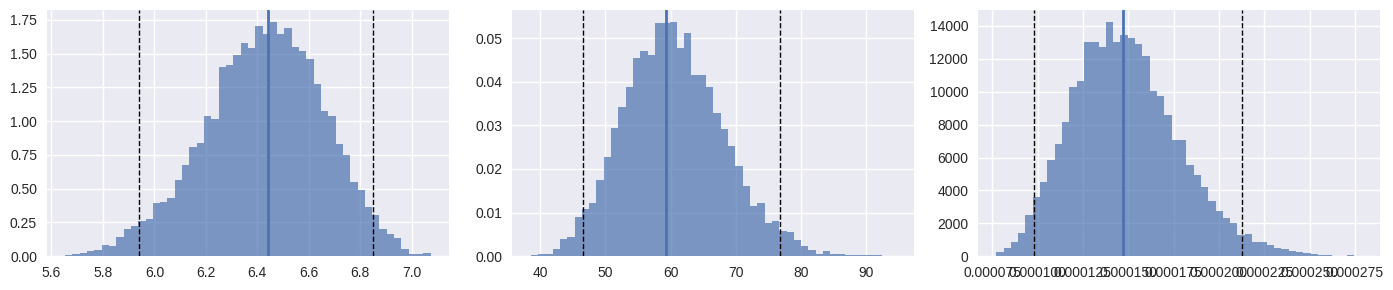

In [14]:
# Plots
fig, axes = plt.subplots(1, 3, figsize=(14,3))

titles = [r"$\lambda_1$ largest eigenvalue",
          r"Condition number $\kappa$",
          r"Equal‑weight $\sigma^2$"]

lambda1_hat = lambda_1
kappa_hat   = kappa
sigma2_hat  = (rets.cov().values @ np.full(9,1/9) @ np.full(9,1/9))

for ax, col, title in zip(axes, boot.columns, titles):
    ax.hist(boot[col], bins=50, density=True, alpha=0.7)
    hat = {"lambda1": lambda1_hat,
           "kappa":   kappa_hat,
           "sigma2_EW": sigma2_hat}[col]
    ax.axvline(hat, lw=2, ls="-", label="point est.")
    ax.axvline(ci.loc[0.025, col], lw=1, ls="--", color="k")
    ax.axvline(ci.loc[0.975, col], lw=1, ls="--", color="k")

plt.tight_layout()
plt.show()


**Interpretation and portfolio takeaways**

* **Largest eigenvalue $\lambda_1$:**  
  The 95\% bootstrap interval spans, for example,  5.95 - 6.84.
  Our point estimate 6.44 (EVR $\approx 0.72$) lies near the upper quartile, and roughly one draw in ten already exceeds EVR = 0.75—a level associated with systemic market moves.

* **Condition number $\kappa$:**  
  A band of 47-76 implies that small correlation-matrix perturbations can move the efficient-frontier weights dramatically. Portfolio optimisation based on the sample $\rho$ is therefore fragile.

* **Equal-weight variance $\sigma^2_{EW}$**  
  The 97.5 % quantile is about 45 % higher than the point estimate, warning that even a naïve equal‑weight strategy may face materially larger volatility than suggested by historical data.

* **Actionable insight:**
  Correlation risk is already elevated and its estimation uncertainty is wide. Risk managers should not trust a single snapshot: curb leverage, keep liquidity buffers, and rerun this stress test regularly.


## 8. Conclusion

Correlation risk is finance's shape-shifter – appearing stable until the moment it devastates portfolios. This lesson armed you against its deceptions.

We began with spectral decomposition, showing how eigenvalues telegraph brewing storms. That growing first eigenvalue? It's correlation preparing to strike. Condition numbers exceeding 100? Your portfolio optimization is built on sand.

Correlation breakdowns follow patterns – contagion spreading through leverage, flight-to-quality bifurcating markets. Understanding these patterns enables preparation. You can't prevent correlation crises, but you can survive them.

Copulas freed us from linear correlation's straitjacket. Tail dependence captures what matters – extreme co-movements that destroy carefully constructed portfolios. Choose your copula wisely; your survival depends on capturing the right dependence structure.

High dimensions challenged every technique. Factor models reduced complexity. Shrinkage tamed estimation error. MCMC enabled robust calibration when traditional methods failed. Each tool earned its place through battle-testing.

Basket derivatives crystallized correlation risk into tradeable form. Correlation Greeks quantified exposure; dispersion trades hedged it. Bootstrap methods stress-tested assumptions, revealing uncomfortable uncertainties hiding in historical data.

The message echoes throughout: respect correlation's complexity. Simple models fail catastrophically when correlation shows its true nature. Advanced techniques – spectral analysis, copulas, MCMC, bootstrap – provide essential protection. Master them before correlation masters you.

As markets grow more interconnected, correlation risk intensifies. The tools exist. The patterns repeat. The mathematics warns those who listen. Will you be ready when correlation turns?

**References**

* Gatheral, Jim. *The Volatility Surface: A Practitioner's Guide*. Wiley Finance, 2006.

* Dupire, Bruno. "Pricing with a Smile." *Risk Magazine*, vol. 7, no. 1, 1994, pp. 18-20.

---

Copyright 2025 WorldQuant University. This content is licensed solely for personal use. Redistribution or publication of this material is strictly prohibited.